In [1]:
from BWM.bwm_analysis import min_trials_per_condition

cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM


ModuleNotFoundError: No module named 'BWM'

In [2]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [3]:
import pandas as pd
import skdim
import scipy

from scipy.stats import gaussian_kde
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [164]:
from scipy.spatial import KDTree
from scipy.stats import norm
def clark_evans_with_pvalue(points, area):
    n = len(points)
    num_dims = points.shape[1]
    density = n / area

    # 1. Nearest Neighbor distances
    tree = KDTree(points)
    distances, _ = tree.query(points, k=2)
    r_obs = np.mean(distances[:, 1])

    # 2. Expected distance (2D specific for this SE formula)
    r_exp = 1 / (2 * np.sqrt(density))

    # 3. Standard Error (for 2D)
    se_r = np.sqrt((4 - np.pi) / (4 * np.pi * n * density))

    # 4. Z-score and P-value (Two-tailed)
    z_score = (r_obs - r_exp) / se_r
    p_value = 2 * (1 - norm.cdf(np.abs(z_score)))

    R = r_obs / r_exp

    return R, z_score, p_value

In [165]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.datasets import make_blobs

# 1. Generate sample data


def find_best_k(data, max_k=10):
    scores = []
    k_range = range(2, max_k + 1) # Silhouette score requires at least 2 clusters

    for k in k_range:
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
        labels = kmeans.fit_predict(data)
        score = silhouette_score(data, labels)
        scores.append(score)
        print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

    # Find the maximum score and its corresponding K
    max_score = max(scores)
    best_k = k_range[scores.index(max_score)]

    return best_k, max_score, scores

In [ ]:
# Loop through data and calculate FID and its correlation with density. Restrict to recordings with >500 neurons.

directory_path = 'Data2'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]
#eids = np.load("eids.npy",allow_pickle=True)
n=[]
d = []
for eid in eids:

    # eid = random.choice(eids)
    full_path_to_random_folder = os.path.join(directory_path, eid)
    print(f"Randomly selected eid: {full_path_to_random_folder}")

    # for _ in range(1):
    neuron_threshold = 500
    dim = 5
    sample_size = 50
    sigma = 5
    n_steps = 100
    threshold = .01
    min_trials_per_condition = 50
    conditions = ['choice']
    event = "stimOn_times"
    clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

    clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

    spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
    trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

    counts_series = clusters.groupby('cosmos').size()
    print(counts_series)

    # shape n_pseudo x n_conditions x time x n
    response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
    spikes, clusters, trials, event, conditions,
    stride=.005,
    step=.005,
    n_steps=n_steps,
    sigma=sigma,
    threshold=threshold,
    min_trials_per_condition=min_trials_per_condition,regions = counts_series.index.values)

    # Restrict to active units
    restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .01,
                             np.std(response_matrix_train, axis=(0, 1, 2)) > .01)
    response_matrix_train = response_matrix_train[
    :, :, :, restriction]

    z = np.mean(response_matrix_train, axis = 0)
    responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                         keepdims=True)) / np.std(z,
                                                                                  axis=(0, 1),
                                                                                  keepdims=True)
    #data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
    #data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
    responses = np.mean(responses, axis=0)
    response_matrix = responses.reshape(-1, responses.shape[2])

    if response_matrix.shape[1]>neuron_threshold:
        # Calculate FID
        pca = PCA().fit(response_matrix.T)
        n_components = np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1
        d.append(n_components)

        fisher = skdim.id.FisherS().fit(response_matrix.T)
        id_fisher = fisher.dimension_
        print(f"FisherS Estimator: {id_fisher:.2f}")
        n.append(id_fisher)



460
Randomly selected eid: Data2/b52182e7-39f6-4914-9717-136db589706e
cosmos
HPF          991
Isocortex    268
MB           261
OLF           12
root          62
void          21
dtype: int64
FisherS Estimator: 4.55
Randomly selected eid: Data2/9fc31d79-b56f-46d0-92a0-e9563caf4a7a
cosmos
HPF           13
Isocortex    210
TH           139
root          15
dtype: int64
Randomly selected eid: Data2/cc45c568-c3b9-4f74-836e-c87762e898c8
cosmos
CNU          315
HPF          125
HY            79
Isocortex    529
MB           308
TH           187
root          81
dtype: int64
FisherS Estimator: 4.47
Randomly selected eid: Data2/e6de6c35-1508-4471-b7c3-f12a5c7a6d39
cosmos
HB      724
MB      195
root     76
dtype: int64
FisherS Estimator: 7.71
Randomly selected eid: Data2/fece187f-b47f-4870-a1d6-619afe942a7d
cosmos
CNU             1
HB           1227
Isocortex     223
MB             98
TH            297
root          261
void           22
dtype: int64
FisherS Estimator: 3.61
Randomly selected e

<Axes: >

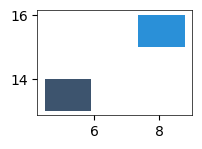

In [191]:

fig = plt.figure(figsize=(2,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1)
ax=fig.add_subplot(gs[0,0])
sns.histplot(x = n, y = d)

lims = [
    np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
    np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
]

# now plot both limits against eachother
ax.plot(lims, lims, 'k-', alpha=0.75, zorder=0)
ax.set_aspect('equal')
ax.set_xlim(lims)
ax.set_ylim(lims)


In [186]:
d = np.argwhere((np.cumsum(pca.explained_variance_ratio_)>.95)==True)[0].item()
d

14

In [187]:
x_proj = PCA(n_components = d).fit_transform(x)

fisher = skdim.id.FisherS().fit(x_proj )
id_fisher = fisher.dimension_
print(f"FisherS Estimator: {id_fisher:.2f}")
FIDS.append(id_fisher)

FisherS Estimator: 7.70


In [161]:
np.save("Silhouettes.npy", Silhouettes)

<Axes: ylabel='Count'>

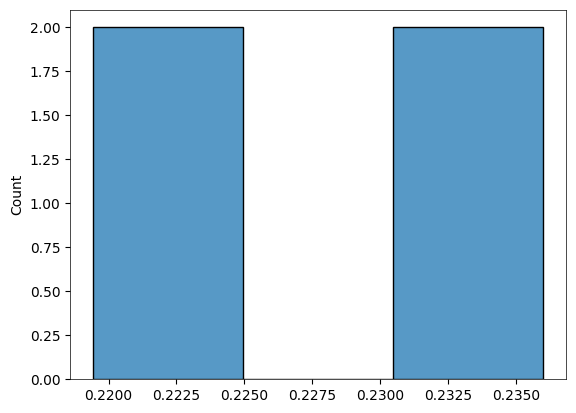

In [160]:
plt.figure()
sns.histplot(x = Clark)

In [131]:
############# Upload data ###########
response_matrix_train = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/response_matrix_train.npy' )
response_matrix_train  = response_matrix_train[:50,:]
condition_matrix_train = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/condition_matrix_train.npy' )
condition_matrix_train  = condition_matrix_train[:50,:]

restriction = np.std(response_matrix_train, axis=(0, 1, 2)) > .1
response_matrix_train = response_matrix_train[
    :, :, :, restriction]

N_NEURONS = response_matrix_train.shape[3]


z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                         keepdims=True)) / np.std(z,
                                                                                  axis=(0, 1),
                                                                                  keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])

In [132]:
# Calculate intrinsic dimension
fisher = skdim.id.FisherS().fit(response_matrix.T)
id_fisher = fisher.dimension_
print(f"FisherS Estimator: {id_fisher:.2f}")

# Calculate correlation between local FID and local density.
x_proj = PCA(n_components = 3).fit_transform(response_matrix.T)
kde = gaussian_kde(x_proj.T)

densities = kde.evaluate(x_proj.T)

FID = skdim.id.FisherS().fit_pw(response_matrix.T, n_neighbors=25)
x = FID.dimension_pw_
y = densities
print(f"Correlation: {scipy.stats.pearsonr(x, y)[0]:.2f}")
print(f"P-Value: {scipy.stats.pearsonr(x, y)[1]:.2f}")

# Calculate uniformity
import numpy as np
from scipy.spatial import KDTree
from scipy.stats import norm


# --- Example usage ---
data = np.random.uniform(0, 100, (500, 2))
R, z, p = clark_evans_with_pvalue(data, 100**2)

print(f"R-Ratio: {R:.4f}")
print(f"Z-score: {z:.4f}")
print(f"P-value: {p:.4f}")

if p < 0.05:
    print("Statistically Significant: Reject the null hypothesis of uniformity.")
else:
    print("Not Significant: Fail to reject the null hypothesis (Distribution is likely uniform).")


FisherS Estimator: 4.41
Correlation: 0.05


In [93]:
import skdim
import numpy as np

# Generate dummy data (e.g., a 5D ball in 10D space)
# data = np.zeros((1000, 10))
# data[:, :5] = skdim.datasets.hyperBall(n=1000, d=5)
data = response_matrix.T
# 1. Global ID Estimation (TwoNN)
twonn = skdim.id.TwoNN().fit(data)
print(f"Global ID: {twonn.dimension_}")

# 2. Local/Pointwise ID Estimation (Local PCA)
lpca = skdim.id.FisherS().fit_pw(data, n_neighbors=25)
print(f"Mean Local ID: {np.mean(lpca.dimension_pw_)}")

Global ID: 9.328698692672656
Mean Local ID: 7.628394728613665


In [33]:
lpca.dimension_pw_

array([ 9,  8,  7,  8,  8,  8,  8,  9,  9,  8,  7,  7,  7,  7,  9,  7,  8,
        6,  7,  8,  7,  8,  8,  7,  9,  7,  8,  8,  8,  7,  9,  9,  8,  7,
        8,  9,  9,  9,  8,  8, 10,  8,  9,  8,  7,  8, 10,  8,  8,  8,  8,
        8,  9,  8,  7,  8,  9,  9,  7,  9,  9,  8,  9,  7, 10,  8,  9,  5,
        7,  9,  8,  9,  9,  8,  7,  8,  7,  8,  8,  6,  7,  9,  8,  8,  8,
        8,  9,  8,  8, 10,  9,  7,  9,  9,  8,  7,  8,  8,  8,  7,  8,  8,
        9,  9,  7,  9,  8,  8,  8,  8,  8,  7,  8,  8,  8,  7, 10,  9,  7,
        8,  8,  7,  8,  9,  8,  9,  7,  9,  8,  8,  9,  8,  8,  8,  8,  8,
        9,  8,  8,  8,  8,  9,  9,  7,  8,  9,  8,  8,  6,  8,  8,  9,  8,
        8,  8,  9,  8,  8,  8,  9,  8,  8,  9,  8,  8,  8,  8,  9,  9,  8,
        9,  9,  9,  8,  7,  8,  9,  7,  8,  9,  8,  9,  8,  7,  7,  7, 10,
        8,  8,  7,  8,  9,  9,  9,  7,  8,  7,  6,  7,  9,  8,  8,  8,  9,
       10,  8,  7,  7,  8,  8,  8,  9,  8,  9,  9,  9,  9,  9,  9,  9,  8,
        7,  8,  9,  8,  9

In [76]:


z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                         keepdims=True)) / np.std(z,
                                                                                  axis=(0, 1),
                                                                                  keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])
##############################################################################################
##############################################################################################

x_proj = TSNE(n_components = 2,perplexity = 200).fit_transform(response_matrix.T)

# import umap
# fit = umap.UMAP(densmap=True,dens_lambda =1)
# x_proj= fit.fit_transform(response_matrix.T)




In [115]:
import numpy as np
from sklearn.neighbors import KernelDensity

from scipy.stats import gaussian_kde
# Example Usage
#points = np.random.normal(0, 1, (100, 2)) # 100 points in 2D
x_proj = PCA(n_components = 3).fit_transform(response_matrix.T)
kde = gaussian_kde(x_proj.T)

densities = kde.evaluate(x_proj.T)

In [102]:
points.shape

(925, 2)

In [110]:
len(densities)

1602

In [111]:
response_matrix.shape

(200, 1602)

In [109]:

plt.figure()
sns.scatterplot(x = densities,y =lpca.dimension_pw_ )

ValueError: All arrays must be of the same length

<Figure size 640x480 with 0 Axes>

In [116]:
len(densities)

925

In [117]:
import numpy as np
import skdim
from sklearn.datasets import make_swiss_roll

# 1. Generate a Non-Linear Dataset
# The Swiss Roll is a 2D sheet (Intrinsic=2) rolled in 3D space (Linear=3)
#data, _ = make_swiss_roll(n_samples=2000, noise=0.1)
data = response_matrix.T
# 2. Maximum Likelihood Estimation (MLE)
# Good for most general cases; assumes a Poisson distribution of points.
mle = skdim.id.MLE().fit(data)
id_mle = mle.dimension_

# 3. FisherS (Fisher Separability)
# Modern method that works well even in very high dimensions.
fisher = skdim.id.FisherS().fit(data)
id_fisher = fisher.dimension_

# 4. Correlation Dimension (CorrInt)
# A classical fractal dimension approach.
corr_int = skdim.id.CorrInt().fit(data)
id_corr = corr_int.dimension_

print(f"Dataset: Swiss Roll (True Intrinsic Dim = 2)")
print("-" * 40)
print(f"MLE Estimator:     {id_mle:.2f}")
print(f"FisherS Estimator: {id_fisher:.2f}")
print(f"CorrInt Estimator: {id_corr:.2f}")

Dataset: Swiss Roll (True Intrinsic Dim = 2)
----------------------------------------
MLE Estimator:     6.89
FisherS Estimator: 4.41
CorrInt Estimator: 2.97


In [89]:
6.89+4.41+2.97

14.270000000000001

In [91]:
14/3

4.666666666666667

In [118]:
x_proj = PCA(n_components = 3).fit_transform(response_matrix.T)
kde = gaussian_kde(x_proj.T)

densities = kde.evaluate(x_proj.T)

FID = skdim.id.FisherS().fit_pw(response_matrix.T, n_neighbors=25)
x = FID.dimension_pw_
y = densities
print(f"Correlation: {scipy.stats.pearsonr(x, y)[0]:.2f}")


Correlation: 0.05


In [31]:
# Load results
df_list = []
for filename in os.listdir('Results'):
    f = os.path.join('Results', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))

df = pd.concat(df_list,ignore_index=True)

#df= df[df.n_neurons>=100]
#df = df[df.n_conditions>1]
#df = df[df.gain<10]
#df.pca_error = np.log10(df.pca_error)

In [32]:
import os

In [33]:
df

,eid,n,d,n_neurons
0,62ff920c-2fdd-4feb-9d9f-0d66f2e595a1,4.587367,20.655869,842
1,cc45c568-c3b9-4f74-836e-c87762e898c8,4.471012,20.475584,1622
2,e1931de1-cf7b-49af-af33-2ade15e8abe7,3.667135,20.695649,1214
3,56b57c38-2699-4091-90a8-aba35103155e,5.397037,20.374710,2184
4,4546cd60-fa2a-4d20-a9b6-d091e01d16f2,7.338605,21.591790,375
...,...,...,...,...
452,41431f53-69fd-4e3b-80ce-ea62e03bf9c7,4.745432,21.223785,2527
453,28741f91-c837-4147-939e-918d38d849f2,8.849450,23.821524,1371
454,cef05f87-161b-4031-932c-6f47daf89698,5.347905,21.401748,727
455,a4a74102-2af5-45dc-9e41-ef7f5aed88be,6.146034,21.628238,1695


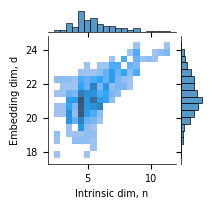

In [48]:

g = sns.jointplot(data = df[df.d>12], x = 'n',y='d',ax=ax,kind = 'hist',height = 2)
g.set_axis_labels('Intrinsic dim, n', 'Embedding dim, d', fontsize=7)
g.ax_joint.tick_params(labelsize=7)
g.savefig("joint_plot.png")
# lims = [
#     np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
#     np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
# ]
#
# # now plot both limits against eachother
# ax.plot(lims, lims, 'k-', alpha=0.5, zorder=0,lw = 1,linestyle='--')
# ax.set_aspect('equal')
# ax.set_xlim(lims)
# ax.set_ylim(lims)
